In [1]:
import argparse
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
from skimage import exposure
from scipy.optimize import nnls
from scipy.sparse import issparse
import squidpy as sq
import math
from collections import defaultdict
from PIL import Image
from skimage import transform
import cv2
from sklearn.preprocessing import MinMaxScaler
import cell2location
from cell2location.utils.filtering import filter_genes
from cell2location.models import RegressionModel
from cell2location.models import Cell2location

/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
def IF_registrar_coord(adata,scale_factor = 0.5,select_channel = "red"):
    # Get the H&E reference image
    
    he_image = adata.uns["spatial"][library_id]["images"]["hires"]

    # Option A: Manual alignment with known scale factor

    if_resized = transform.resize(
        if_image,
        (he_image.shape[0], he_image.shape[1])
    )
    

    if select_channel == "red":
        if_resized = if_resized[:, :, 0]

    # Option B: Automatic registration using OpenCV
    # Convert to uint8 for cv2
    #he_gray = (he_image.mean(axis=-1) * 255).astype(np.uint8)
    #if_gray = (if_image * 255).astype(np.uint8)

    
    # Find transformation matrix
    #orb = cv2.ORB_create()
    #kp1, des1 = orb.detectAndCompute(he_gray, None)
    #kp2, des2 = orb.detectAndCompute(if_gray, None)

    #matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
    #matches = matcher.match(des1, des2)
    #matches = sorted(matches, key=lambda x: x.distance)

    # Use top matches for homography
    #src_pts = np.float32([kp1[m.queryIdx].pt for m in matches[:50]]) 
    #dst_pts = np.float32([kp2[m.trainIdx].pt for m in matches[:50]])

    #M, _ = cv2.findHomography(dst_pts, src_pts, cv2.RANSAC)
    #if_registered = cv2.warpPerspective(if_gray, M, 
    #                                 (he_gray.shape[1], he_gray.shape[0]))

    
    # Extract IF Intensity per Spot
    coords = adata.obsm["spatial"]   # (n_spots, 2) array of x,y coordinates
    scale  = adata.uns["spatial"][library_id]["scalefactors"]["tissue_hires_scalef"]

    # Extract mean IF intensity in a window around each spot
    spot_radius = 8   # pixels, adjust to spot size

    if_intensities = []

    for x, y in coords:
        # Scale coordinates to image space
        xi = int(x * scale)
        yi = int(y * scale)
    
        # Extract patch around spot
        patch = if_resized[
            max(0, yi - spot_radius):yi + spot_radius,
            max(0, xi - spot_radius):xi + spot_radius
        ]
    
        if_intensities.append(patch.mean())

    # Add to adata.obs
    adata.obs["IF_intensity"] = if_intensities
    #print(adata.obs["IF_intensity"].describe())

    return if_intensities

In [3]:
def marker_unique_excel(exl_file,sheet_name,cluster = "supertype.markers.combo",class_label = "class_label"):

    """
        split marker unique genes into class. Based on Allen Mouse Brain.

    """
    markers_df = pd.read_excel(exl_file,sheet_name=sheet_name)

    #interested in supertype.markers.combo and class_label and class_id_label
    markers_df = markers_df[[cluster,class_label]]
    markers_df = markers_df.dropna(subset=[cluster])
    #markers_df.to_csv("test.csv", index=False)

    markers_df['gene_list'] = markers_df[cluster].str.split(',').apply(
        lambda x: [g.strip() for g in x]
    )

    genes_long = (
        markers_df[[cluster, class_label]]
        .assign(gene=markers_df[cluster].str.split(','))
        .explode('gene')
    )

    genes_long['gene'] = genes_long['gene'].str.strip()
    genes_long = genes_long[genes_long['gene'] != '']  # remove empty strings

    gene_class_count = (
        genes_long.groupby('gene')[class_label]
        .nunique()
        .rename('n_classes')
    )

    unique_genes = gene_class_count[gene_class_count == 1].index

    unique_table = (
        genes_long[genes_long['gene'].isin(unique_genes)]
        [[class_label, 'gene']]
        .drop_duplicates()
        .sort_values([class_label, 'gene'])
        .reset_index(drop=True)
    )


    unique_marker_dict = (
        unique_table.groupby(class_label)['gene']
        .apply(list)
        .to_dict()
    )
        
    return unique_table, unique_marker_dict

In [4]:
def marker_unique_excel_subclass(exl_file,sheet_name,cluster = "supertype.markers.combo",class_label = "class_label",subclass_label = "subclass_label"):
    """
        split marker unique genes into class and subclass.  Based on Allen Mouse Brain.
        Note: preserving unique genes between supertype but NOT subclass.  May need to change...

    """

    markers_df = pd.read_excel(exl_file,sheet_name=sheet_name)

    markers_df = markers_df[[cluster,class_label,subclass_label]]
    markers_df = markers_df.dropna(subset=[cluster])
    

    markers_df['gene_list'] = markers_df[cluster].str.split(',').apply(
        lambda x: [g.strip() for g in x]
    )

    genes_long = (
        markers_df[[cluster, class_label,subclass_label]]
        .assign(gene=markers_df[cluster].str.split(','))
        .explode('gene')
    )

    genes_long['gene'] = genes_long['gene'].str.strip()
    genes_long = genes_long[genes_long['gene'] != '']  # remove empty strings

    gene_class_count = (
        genes_long.groupby('gene')[class_label]
        .nunique()
        .rename('n_classes')
    )

    unique_genes = gene_class_count[gene_class_count == 1].index

    unique_table = (
        genes_long[genes_long['gene'].isin(unique_genes)]
        [[class_label, subclass_label,'gene']]
        .drop_duplicates()
        .sort_values([class_label, 'gene'])
        .reset_index(drop=True)
    )

  
    unique_marker_dict = defaultdict(lambda: defaultdict(list))

    for _, row in unique_table.iterrows():
        unique_marker_dict[row[class_label]][row[subclass_label]].append(row["gene"])

    unique_marker_dict = {k: dict(v) for k, v in unique_marker_dict.items()}
        
    return unique_table, unique_marker_dict

In [5]:
def minimum_threshold_gene_filter(adata,markers,min_markers=3):

    filtered_markers = {}
    for ct, genes in markers.items():
        present  = [g for g in genes if g in adata.var_names]
        detected = [g for g in present
                if (adata[:, g].X > 0).sum() > adata.n_obs * 0.01]  # >1% spots
        filtered_markers[ct] = detected
        print(f"  {ct:30s}  {len(detected):3d}/{len(genes):3d} detected")

    # Drop cell types with too few markers
    valid_cts = {ct: g for ct, g in filtered_markers.items() if len(g) >= min_markers}
    print(f"\n{len(valid_cts)} cell types with >= {min_markers} detected markers")

    return valid_cts

In [6]:
def weighted_score(adata, genes, min_detection=0.01):
    """
    Weight each gene by its detection rate across spots.
    Downweights genes that are rarely detected (unreliable at 8um).
    """
    present = [g for g in genes if g in adata.var_names]
    if not present:
        return np.zeros(adata.n_obs)

    expr = adata[:, present].X
    if hasattr(expr, 'toarray'):
        expr = expr.toarray()

    # Detection rate per gene
    detection = (expr > 0).mean(axis=0)

    # Only use genes detected in >1% of spots
    mask = detection >= min_detection
    if mask.sum() == 0:
        return np.zeros(adata.n_obs)

    expr     = expr[:, mask]
    detection = detection[mask]

    # Weight by detection rate
    weights  = detection / detection.sum()

    return expr @ weights

In [7]:
def nnls_deconvolve(adata, markers_dict, n_jobs=-1):
    """
    Non-negative least squares deconvolution.
    Fits cell type proportions to observed expression.
    """
    # Build signature matrix — mean expression per cell type
    # Using only genes in your marker dict
    all_genes = list({g for genes in markers_dict.values()
                      for g in genes if g in adata.var_names})
    ct_names  = list(markers_dict.keys())

    # Signature: average normalized expression of marker genes per cell type
    # Here we use detection-weighted mean as proxy for signature
    sig = np.zeros((len(all_genes), len(ct_names)))
    gene_idx = {g: i for i, g in enumerate(all_genes)}

    for j, (ct, genes) in enumerate(markers_dict.items()):
        present = [g for g in genes if g in adata.var_names]
        for g in present:
            expr = adata[:, g].X
            if issparse(expr):
                expr = expr.toarray().flatten()
            sig[gene_idx[g], j] = expr.mean()

    # Get spot expression for those genes
    X = adata[:, all_genes].X
    if issparse(X):
        X = X.toarray()

    # NNLS per spot
    props = np.zeros((adata.n_obs, len(ct_names)))
    for i in range(adata.n_obs):
        props[i], _ = nnls(sig, X[i])

    # Normalize to sum to 1
    row_sums = props.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    props = props / row_sums

    prop_df = pd.DataFrame(props, index=adata.obs_names,
                           columns=[f"nnls_{ct}" for ct in ct_names])
    return prop_df

In [8]:
def high_confidence_assignment(adata, valid_cts,
                                score_pct=75,    # percentile threshold
                                min_methods=2):  # must pass N methods
    """
    Assign cell type only if multiple scoring methods agree.
    """
    ct_names = list(valid_cts.keys())
    n_spots  = adata.n_obs
    votes    = np.zeros((n_spots, len(ct_names)), dtype=int)

    for j, ct in enumerate(ct_names):
        # Method A — scanpy score
        if f"tlscore_{ct}" in adata.obs:
            s = adata.obs[f"tlscore_{ct}"].values
            thresh = np.percentile(s, score_pct)
            votes[:, j] += (s >= thresh).astype(int)

        # Method B — weighted score
        if f"wscore_{ct}" in adata.obs:
            s = adata.obs[f"wscore_{ct}"].values
            thresh = np.percentile(s, score_pct)
            votes[:, j] += (s >= thresh).astype(int)

        # Method C — NNLS proportion
        if f"nnls_{ct}" in adata.obs:
            s = adata.obs[f"nnls_{ct}"].values
            thresh = np.percentile(s, score_pct)
            votes[:, j] += (s >= thresh).astype(int)

    # Assign cell type if >= min_methods agree
    max_votes   = votes.max(axis=1)
    best_ct_idx = votes.argmax(axis=1)

    assignments = np.where(
        max_votes >= min_methods,
        np.array(ct_names)[best_ct_idx],
        "unassigned"
    )

    # Confidence score = fraction of methods agreeing / max possible
    confidence = max_votes / 3.0

    adata.obs['celltype_assignment']  = assignments
    adata.obs['assignment_confidence'] = confidence
    adata.obs['assignment_votes']      = max_votes

    # Summary
    counts = pd.Series(assignments).value_counts()
    print(f"\nAssignment summary (min {min_methods}/3 methods):")
    print(counts.to_string())
    print(f"\nUnassigned: {(assignments=='unassigned').sum()} "
          f"({(assignments=='unassigned').mean()*100:.1f}%)")
    print(f"High confidence (all 3 agree): {(max_votes==3).sum()} spots")

    return adata

In [9]:
def plot_celltype_overlay(adata, celltypes, img_key="hires", 
                          spot_size=1.4, alpha=0.7, min_threshold=0.3,
                          figsize=(10, 10),border_color="white",colors = cm.tab20.colors,crop_coord=None):
    """
    Overlay multiple cell types on the same spatial image.
    Each cell type gets a distinct color; spots are only shown
    if their score exceeds min_threshold (as a percentile).
    """
    library_id = list(adata.uns["spatial"].keys())[0]
    img = adata.uns["spatial"][library_id]["images"][img_key]
    scale = adata.uns["spatial"][library_id]["scalefactors"][f"tissue_{img_key}_scalef"]
    
    # Get spot coordinates (in image pixel space)
    coords = adata.obsm["spatial"] * scale  # shape: (n_spots, 2)
    
    # ── Resolve zoom from crop_coord if provided ──────────────────────────────
    if crop_coord is not None:
        x_min, y_min, x_max, y_max = crop_coord
        xlim = (x_min, x_max)
        ylim = (y_max, y_min)   # inverted: imshow origin is top-left

        # Crop the image array to avoid rendering the full tissue
        img = img[y_min:y_max, x_min:x_max]

        # Shift coordinates so they align with the cropped image
        coords = coords.copy()
        coords[:, 0] -= x_min
        coords[:, 1] -= y_min

        # Recompute limits in cropped space
        xlim = (0, x_max - x_min)
        ylim = (y_max - y_min, 0)   # still inverted

    
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(img,alpha = 0.4)
    ax.axis("off")
    
    legend_handles = []
    
    for i, ct in enumerate(celltypes):
        if ct not in adata.obs.columns:
            print(f"Warning: {ct} not found in adata.obs, skipping")
            continue
        
        scores = adata.obs[ct].values
        
        # Only plot spots above threshold percentile
        threshold = np.percentile(scores, min_threshold * 100)
        mask = scores > threshold
        
        # Normalize scores for alpha/size scaling
        s_norm = (scores[mask] - scores[mask].min()) / (scores[mask].max() - scores[mask].min() + 1e-8)
        
        color = colors[i % len(colors)]
        

        # ── Draw border layer first (slightly larger, neon color) ─────────────────
        scatter = ax.scatter(
            coords[mask, 0],
            coords[mask, 1],
            s=spot_size * (1 + s_norm * 3), #spot_size * 1.6, #spot_size * (1 + s_norm * 3),        # slightly bigger than fill
            c=border_color,
            linewidths=1,
            alpha=alpha,
            zorder=2,
        )

        legend_handles.append(scatter)
        
        # ── Draw filled spots on top ───────────────────────────────────────────────
        sc_fill = ax.scatter(
            coords[mask, 0], 
            coords[mask, 1],
            s=spot_size * (1 + s_norm * 3),
            c=[color],
            linewidths=0,
            alpha=alpha,
            zorder=3,
            label=ct, 
        )
        legend_handles.append(sc_fill)
    
    ax.legend(
        loc="upper right",
        bbox_to_anchor=(1.3, 1),
        fontsize=7,
        markerscale=2,
        framealpha=0.8,
    )

    plt.title("Cell type overlay", fontsize=12)
    plt.tight_layout()
    return fig

## Setup input files

In [194]:
#adata = sc.read_h5ad("../data/processed/Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_008um.h5ad")
#label = "Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_008um"
adata = sc.read_h5ad("../data/processed/Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_7_D1_GFP_R1_008um.h5ad")
label = "Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_7_D1_GFP_R1_008um"
#adata = sc.read_h5ad(""../data/processed/Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_016um.h5ad")
#label = "Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_016um"
#adata = sc.read_h5ad(""../data/processed/Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_7_D1_GFP_R1_016um.h5ad")
#label = "Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_7_D1_GFP_R1_016um"
#adata = sc.read_h5ad("../data/processed/Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_J74_3_A1_GFP_R1_008um.h5ad")
#label = "Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_J74_3_A1_GFP_R1_008um"
#adata = sc.read_h5ad(""../data/processed/Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_J74_3_A1_GFP_R1_016um.h5ad")
#label = "Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_J74_3_A1_GFP_R1_016um"
#adata = sc.read_h5ad("../data/processed/Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_J75_3_D1_GFP_R1_008um.h5ad")
#label = "Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_J75_3_D1_GFP_R1_008um"
#adata = sc.read_h5ad(""../data/processed/Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_J75_3_D1_GFP_R1_016um.h5ad")
#label = "Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_J75_3_D1_GFP_R1_016um"
marker_table_allen_subclass,marker_allen_subclass = marker_unique_excel_subclass('/research/groups/mackgrp/home/demerson/AIB/yao_et_al_Nature_2023.xlsx','supertype_annotation')
marker_table_allen,marker_allen = marker_unique_excel('/research/groups/mackgrp/home/demerson/AIB/yao_et_al_Nature_2023.xlsx','supertype_annotation')
#remove ct with < 3 genes in adata
marker_allen = minimum_threshold_gene_filter(adata,marker_allen)

marker_allen['gfp_probe'] = ['Gfp', 'GFP', 'EGFP', 'eGFP', 'gfp', 'egfp','EGFP-L10a', 'Gfp-L10a', 'td-Tomato', 'mCherry']
tumor = {}
instance = pd.read_excel("../reference/93_core_gene_set_commonly_upregulated_in_human_and_mouse_C11orf95_RELAFUS1_driven_ependymoma.xlsx",sheet_name="Sheet1",header=None)
tumor['C11orf95_relafus1'] = instance[0].str.capitalize().tolist()


  Astro-Epen                       18/ 34 detected
  CB GABA                           5/  9 detected
  CB Glut                           1/  1 detected
  CNU-HYa GABA                     19/ 41 detected
  CNU-HYa Glut                      9/ 24 detected
  CNU-LGE GABA                     18/ 30 detected
  CNU-MGE GABA                      3/ 12 detected
  CTX-CGE GABA                      9/ 18 detected
  CTX-MGE GABA                     13/ 26 detected
  DG-IMN Glut                       2/  7 detected
  HY GABA                          15/ 38 detected
  HY Glut                          13/ 40 detected
  HY Gnrh1 Glut                     0/  1 detected
  HY MM Glut                        0/  1 detected
  IT-ET Glut                       49/115 detected
  Immune                            4/ 12 detected
  LSX GABA                         12/ 29 detected
  MB Dopa                           1/  4 detected
  MB GABA                          10/ 30 detected
  MB Glut                      

## Scoring spots at GFP signal location

Scoring using tl.score approach and select maximum score

In [203]:

for ct, genes in marker_allen.items():
    #n = score_geneset(adata, genes, ct)
    sc.tl.score_genes(
        adata,
        gene_list=genes,
        score_name= f"tlscore_{ct}",
        use_raw=False
    )

for ct, genes in tumor.items():
    sc.tl.score_genes(
        adata,
        gene_list=genes,
        score_name= f"tltumscore_{ct}",
        use_raw=False
    )

       'td-Tomato', 'mCherry'],
      dtype='object')


## Create normalized scores

In [204]:
score_cols = []
for ct, genes in marker_allen.items():
    score_cols.append('tlscore_' + ct)
score_cols.append('tltumscore_C11orf95_relafus1')

norm_threshold = 0.07
score_cols_norm = []
for col in score_cols:
        if col not in adata.obs.columns:
            print(f"Skipping '{col}': not found in adata.obs")
            continue#

        norm_col  = f"norm_{col}"#

        s = adata.obs[col]
        adata.obs[norm_col] = (s - s.min()) / (s.max() - s.min())
        print(f"Normalized '{col}' → '{norm_col}'")

        adata.obs[norm_col] = adata.obs[norm_col].where(
            adata.obs[norm_col] > norm_threshold
        )
        n_passing = (adata.obs[norm_col] >= norm_threshold).sum()
        n_total   = len(adata.obs[norm_col])
        print(f"Threshold applied → '{norm_col}' | {n_passing}/{n_total} spots pass ({100*n_passing/n_total:.1f}%)")
        score_cols_norm.append(norm_col)


Normalized 'tlscore_Astro-Epen' → 'norm_tlscore_Astro-Epen'
Threshold applied → 'norm_tlscore_Astro-Epen' | 208596/208874 spots pass (99.9%)
Normalized 'tlscore_CB GABA' → 'norm_tlscore_CB GABA'
Threshold applied → 'norm_tlscore_CB GABA' | 200437/208874 spots pass (96.0%)
Normalized 'tlscore_CNU-HYa GABA' → 'norm_tlscore_CNU-HYa GABA'
Threshold applied → 'norm_tlscore_CNU-HYa GABA' | 208565/208874 spots pass (99.9%)
Normalized 'tlscore_CNU-HYa Glut' → 'norm_tlscore_CNU-HYa Glut'
Threshold applied → 'norm_tlscore_CNU-HYa Glut' | 208577/208874 spots pass (99.9%)
Normalized 'tlscore_CNU-LGE GABA' → 'norm_tlscore_CNU-LGE GABA'
Threshold applied → 'norm_tlscore_CNU-LGE GABA' | 208685/208874 spots pass (99.9%)
Normalized 'tlscore_CNU-MGE GABA' → 'norm_tlscore_CNU-MGE GABA'
Threshold applied → 'norm_tlscore_CNU-MGE GABA' | 202117/208874 spots pass (96.8%)
Normalized 'tlscore_CTX-CGE GABA' → 'norm_tlscore_CTX-CGE GABA'
Threshold applied → 'norm_tlscore_CTX-CGE GABA' | 207459/208874 spots pass 

# Assign prediction based on score max (unnormalized)

In [205]:
score_cols = [c for c in adata.obs.columns if c.startswith("tlscore_")]
scores = adata.obs[score_cols].copy()
#scores.columns = [c.replace("score_", "") for c in score_cols]

top2 = np.sort(scores.values, axis=1)[:, -2:]
margin = top2[:, 1] - top2[:, 0]   # best minus second-best
adata.obs["tlcelltype_assigned"] = scores.idxmax(axis=1)
adata.obs["tlcelltype_score"] = scores.max(axis=1)
adata.obs["tlcelltype_margin"] = margin

# Require both absolute score AND separation from runner-up
low_conf = (adata.obs["tlcelltype_score"] < 0.1) | (adata.obs["tlcelltype_margin"] < 0.05)
adata.obs.loc[low_conf, "tlcelltype_assigned"] = "Unknown"

/lsf_tmp/295769326.tmpdir/ipykernel_1902594/900044131.py:11: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  gfp_adata.obs["tlcelltype_assigned"] = scores_df.idxmax(axis=1)


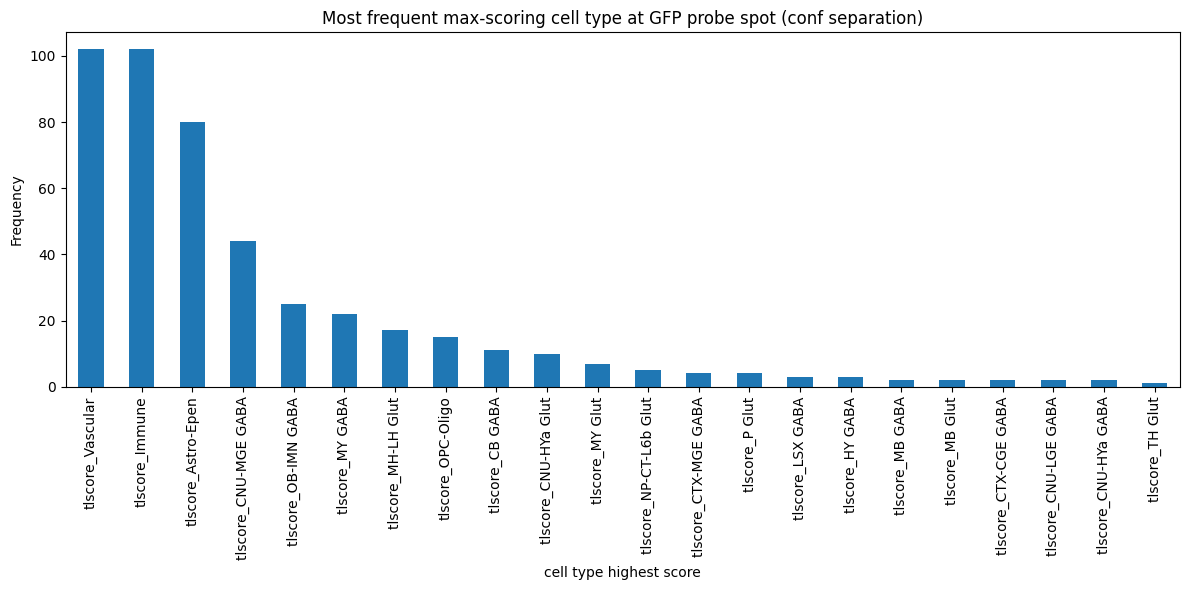

In [206]:
gfp_adata = adata[adata.obs['tlcelltype_assigned'] == "tlscore_gfp_probe"]

#reassign from gfp to class
score_cols = [c for c in gfp_adata.obs.columns if c.startswith("tlscore_")]
scores_df = gfp_adata.obs[score_cols].copy()
#gfp removed from consideration
scores_df = scores_df.drop(columns=["tlscore_gfp_probe"])

top2 = np.sort(scores_df.values, axis=1)[:, -2:]
margin = top2[:, 1] - top2[:, 0]   # best minus second-best
gfp_adata.obs["tlcelltype_assigned"] = scores_df.idxmax(axis=1)
gfp_adata.obs["tlcelltype_score"] = scores_df.max(axis=1)
gfp_adata.obs["tlcelltype_margin"] = margin

low_conf = (gfp_adata.obs["tlcelltype_score"] < 0.1) | (gfp_adata.obs["tlcelltype_margin"] < 0.05)
gfp_adata.obs.loc[low_conf, "tlcelltype_assigned"] = "Unknown"
gfp_adata_mod =  gfp_adata[gfp_adata.obs["tlcelltype_assigned"] != "Unknown"]
counts = gfp_adata_mod.obs["tlcelltype_assigned"].value_counts()

ax = counts.plot(
        kind="bar",
        figsize=(12, 6))

ax.set_xlabel("cell type highest score")
ax.set_ylabel("Frequency")
ax.set_title("Most frequent max-scoring cell type at GFP probe spot (conf separation)")
plt.tight_layout()

## Further subset gfp + immune into subclass

/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


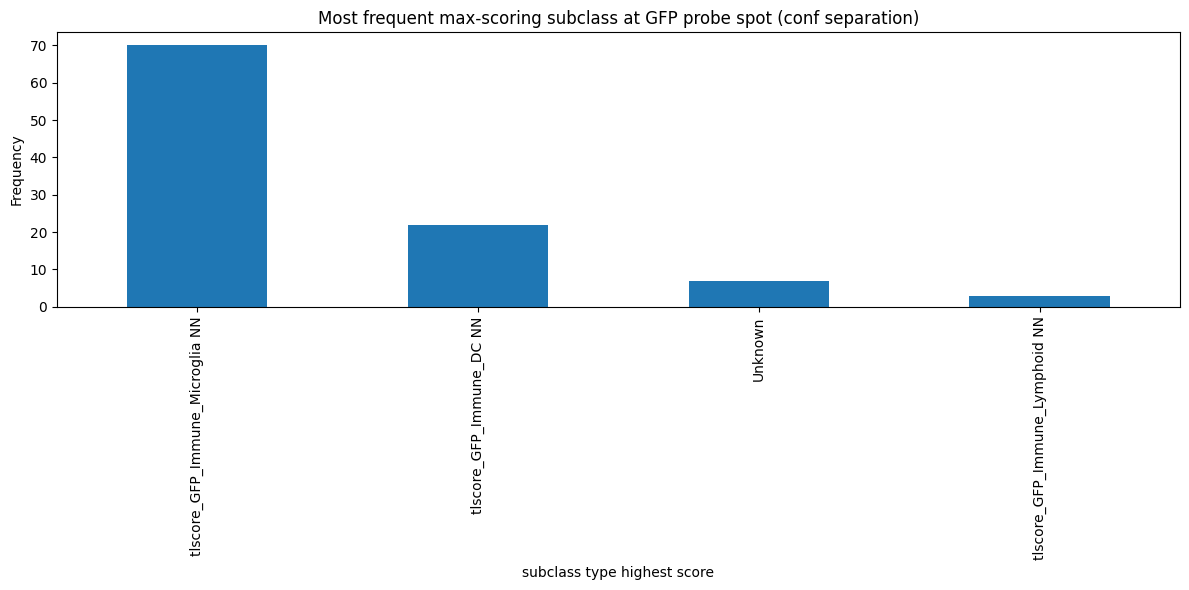

In [207]:
gfp_immune_adata = gfp_adata[gfp_adata.obs["tlcelltype_assigned"] == "tlscore_Immune"]
#marker_allen_subclass["Immune"]
for ct, genes in marker_allen_subclass["Immune"].items():
    #n = score_geneset(adata, genes, ct)
    sc.tl.score_genes(
        gfp_immune_adata,
        gene_list=genes,
        score_name= f"tlscore_GFP_Immune_{ct}",
        use_raw=False
    )

score_cols = [c for c in gfp_immune_adata.obs.columns if c.startswith("tlscore_GFP_Immune_")]
scores_df = gfp_immune_adata.obs[score_cols].copy()

top2 = np.sort(scores_df.values, axis=1)[:, -2:]
margin = top2[:, 1] - top2[:, 0]   # best minus second-best
gfp_immune_adata.obs["tlcelltype_subclass_assigned"] = scores_df.idxmax(axis=1)
gfp_immune_adata.obs["tlcelltype_subclass_score"] = scores_df.max(axis=1)
gfp_immune_adata.obs["tlcelltype_subclass_margin"] = margin

low_conf = (gfp_immune_adata.obs["tlcelltype_subclass_score"] < 0.1) | (gfp_immune_adata.obs["tlcelltype_subclass_margin"] < 0.05)
gfp_immune_adata.obs.loc[low_conf, "tlcelltype_subclass_assigned"] = "Unknown"
gfp_immune_adata_mod =  gfp_immune_adata[gfp_immune_adata.obs["tlcelltype_subclass_assigned"] != "Unknown"]
counts = gfp_immune_adata.obs["tlcelltype_subclass_assigned"].value_counts()

ax = counts.plot(
        kind="bar",
        figsize=(12, 6))

ax.set_xlabel("subclass type highest score")
ax.set_ylabel("Frequency")
ax.set_title("Most frequent max-scoring subclass at GFP probe spot (conf separation)")
plt.tight_layout()

gfp_immune_adata_tlscore_conf = gfp_immune_adata.copy()

In [208]:
score_cols = []
for ct, genes in marker_allen.items():
    score_cols.append('tlscore_' + ct)
score_cols

['tlscore_Astro-Epen',
 'tlscore_CB GABA',
 'tlscore_CNU-HYa GABA',
 'tlscore_CNU-HYa Glut',
 'tlscore_CNU-LGE GABA',
 'tlscore_CNU-MGE GABA',
 'tlscore_CTX-CGE GABA',
 'tlscore_CTX-MGE GABA',
 'tlscore_HY GABA',
 'tlscore_HY Glut',
 'tlscore_IT-ET Glut',
 'tlscore_Immune',
 'tlscore_LSX GABA',
 'tlscore_MB GABA',
 'tlscore_MB Glut',
 'tlscore_MH-LH Glut',
 'tlscore_MY GABA',
 'tlscore_MY Glut',
 'tlscore_NP-CT-L6b Glut',
 'tlscore_OB-IMN GABA',
 'tlscore_OPC-Oligo',
 'tlscore_P GABA',
 'tlscore_P Glut',
 'tlscore_TH Glut',
 'tlscore_Vascular',
 'tlscore_gfp_probe']

In [209]:
#from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

score_cols = []
for ct, genes in marker_allen.items():
    if ct != 'gfp_probe':
        score_cols.append('tlscore_' + ct)
scores_df = adata.obs[score_cols].copy()
#scores_df.drop(columns=["tlscore_gfp_probe"], inplace=True)

scores_norm = pd.DataFrame(
    scaler.fit_transform(scores_df),
    index   = scores_df.index,
    columns = score_cols #[c.replace("score_", "") for c in score_cols]
)

# Assign based on normalized scores
min_threshold = 0.3

max_norm_scores = scores_norm.max(axis=1)

adata.obs["celltype_assigned_norm"] = np.where(
    max_norm_scores >= min_threshold,
    scores_norm.idxmax(axis=1),
    "Unassigned"
)



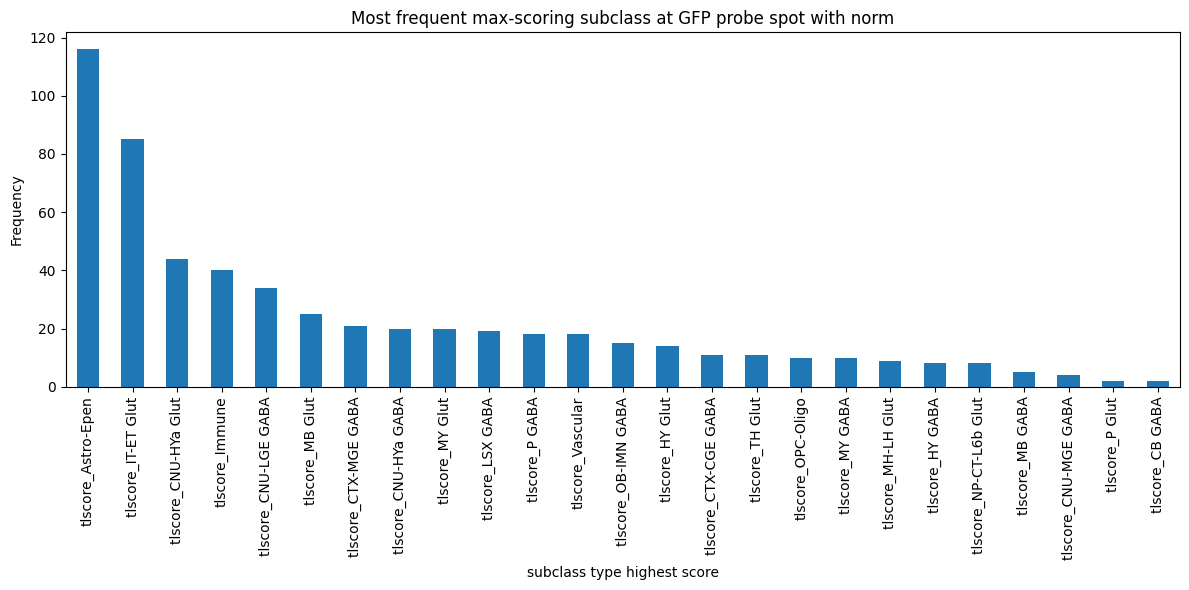

In [210]:
gfp_adata = adata[adata.obs['tlcelltype_assigned'] == "tlscore_gfp_probe"]
counts = gfp_adata.obs["celltype_assigned_norm"].value_counts()

ax = counts.plot(
        kind="bar",
        figsize=(12, 6))

ax.set_xlabel("subclass type highest score")
ax.set_ylabel("Frequency")
ax.set_title("Most frequent max-scoring subclass at GFP probe spot with norm")
plt.tight_layout()


In [211]:
loupe_export = adata.obs[[
    "tlcelltype_assigned",
    "celltype_assigned_norm"
]].reset_index()
loupe_export.columns = ["Barcode", "tlcelltype_assigned", "celltype_assigned_norm"]

filename = "../for_loupe/spatial_" + label +  "_for_loupe.csv"
loupe_export.to_csv(filename, index=False)
print(f"Exported {len(loupe_export)} spots")


Exported 208874 spots


In [212]:
a = loupe_export["tlcelltype_assigned"]
b = loupe_export["celltype_assigned_norm"]

jaccard = (a == b).sum() / len(loupe_export)

In [213]:
jaccard

np.float64(0.30671601060926684)

## Plot gfp spots

In [214]:
threshold = 0.07
adata_filtered = adata[adata.obs["tlscore_gfp_probe_norm"] > threshold].copy()

fig, ax = plt.subplots(figsize=(10, 10))

sq.pl.spatial_scatter(
    adata_filtered,
    img_res_key="hires",
    img_alpha = 0.8,
    color='tlscore_gfp_probe_norm',
    size=5.0,
    alpha=1.0,
    dpi=300,
    ax = ax,
    title='tlscore gfp probe norm',
)

ax.set_facecolor("none")
fig.patch.set_facecolor("none")

KeyError: 'tlscore_gfp_probe_norm'

## NNLS

In [215]:
prop_df = nnls_deconvolve(adata, marker_allen)


In [216]:
new_cols = prop_df.columns.difference(adata.obs.columns)

if len(new_cols) > 0:
    adata.obs = adata.obs.join(prop_df[new_cols])
else:
    print("All columns already exist in adata.obs, skipping join.")

# plot gfp spots

/lsf_tmp/295769326.tmpdir/ipykernel_1902594/1234706136.py:10: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  gfp_adata.obs["nnls_predicted_celltype"] = scores_df["predicted_celltype"]


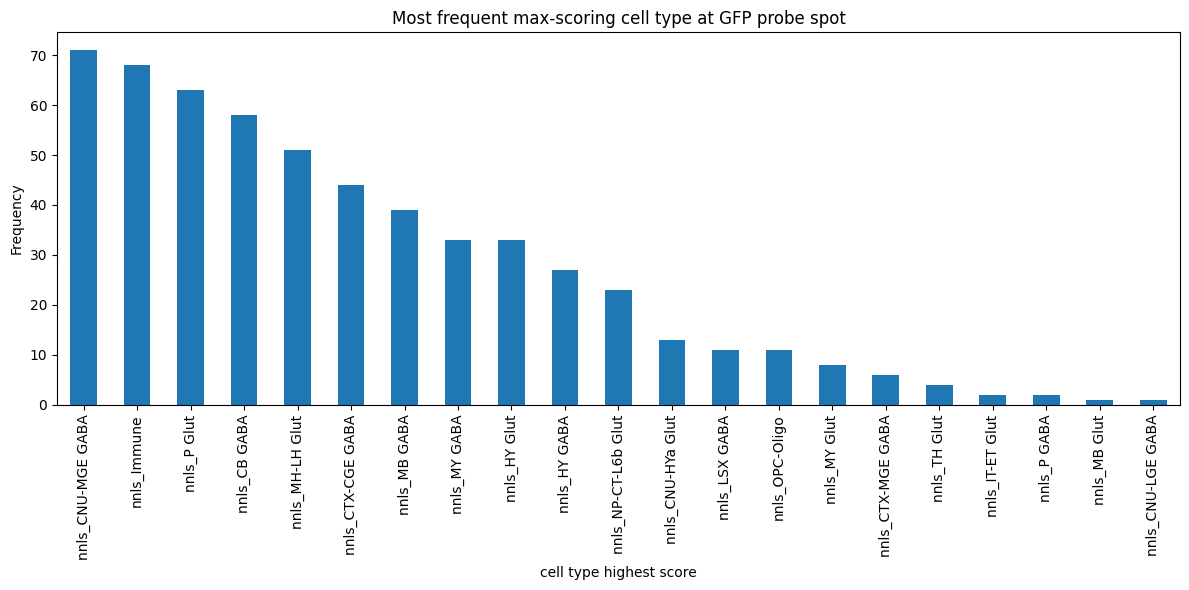

In [217]:
gfp_adata = adata[adata.obs['nnls_gfp_probe'] > 0]
gfp_scores = gfp_adata.obs['nnls_gfp_probe'].values

select_scores = ["nnls_" + k for k in marker_allen.keys()]

scores_df = gfp_adata.obs[select_scores]
scores_df = scores_df.drop(columns=["nnls_gfp_probe"])
scores_df["predicted_celltype"] = scores_df.idxmax(axis=1)
counts = scores_df["predicted_celltype"].value_counts()
gfp_adata.obs["nnls_predicted_celltype"] = scores_df["predicted_celltype"]

ax = counts.plot(
        kind="bar",
        figsize=(12, 6))

ax.set_xlabel("cell type highest score")
ax.set_ylabel("Frequency")
ax.set_title("Most frequent max-scoring cell type at GFP probe spot")
plt.tight_layout()

# total cells

In [218]:
select_scores = ["nnls_" + k for k in marker_allen.keys()]

scores_df = adata.obs[select_scores]
#scores_df = scores_df.drop(columns=["nnls_gfp_probe"])
scores_df["predicted_celltype"] = scores_df.idxmax(axis=1)
adata.obs["nnls_celltype_assigned"] = scores_df["predicted_celltype"]

/lsf_tmp/295769326.tmpdir/ipykernel_1902594/4253110856.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  scores_df["predicted_celltype"] = scores_df.idxmax(axis=1)


In [219]:
adata.obs["nnls_celltype_assigned"]

s_008um_00260_00253-1      nnls_CNU-HYa Glut
s_008um_00819_00322-1           nnls_MB GABA
s_008um_00469_00254-1           nnls_TH Glut
s_008um_00674_00375-1      nnls_CNU-HYa GABA
s_008um_00220_00651-1           nnls_MB GABA
                                ...         
s_008um_00065_00410-1           nnls_MY GABA
s_008um_00506_00476-1           nnls_HY Glut
s_008um_00068_00328-1           nnls_CB GABA
s_008um_00655_00060-1    nnls_NP-CT-L6b Glut
s_008um_00630_00099-1           nnls_CB GABA
Name: nnls_celltype_assigned, Length: 208874, dtype: object

In [220]:
loupe_export = adata.obs[[
    "tlcelltype_assigned",
    "celltype_assigned_norm",
    "nnls_celltype_assigned",
]].reset_index()
loupe_export.columns = ["Barcode", "tlcelltype_assigned", "celltype_assigned_norm",
                        "nnls_celltype_assigned"] #"norm_tltumscore_C11orf95_relafus1","norm_tlscore_gfp_probe"]

col = "norm_tltumscore_C11orf95_relafus1"

loupe_export[col] = np.where(
    adata.obs[col].values > 0.07,
    col,
    "not fusion"
)

col2 = "norm_tlscore_gfp_probe"
loupe_export[col2] = np.where(
    adata.obs[col2].values > 0.07,   # adjust threshold as needed
    col2,
    "not gfp"
)


#loupe_export["norm_tlscore_gfp_probe"] = pd.to_numeric(loupe_export["norm_tlscore_gfp_probe"], errors="coerce").fillna(0).astype(int)

filename = "../for_loupe/spatial_" + label +  "_for_loupe.csv"
loupe_export.to_csv(filename, index=False)
#print(f"Exported {len(loupe_export)} spots")

In [221]:
a = loupe_export["nnls_celltype_assigned"].str.replace("nnls_", "tlscore_", regex=False)
b = loupe_export["celltype_assigned_norm"]

jaccard = (a == b).sum() / len(loupe_export)

In [222]:
jaccard

np.float64(0.20962877141243047)

In [223]:
loupe_export["celltype_assigned_norm"]


0         tlscore_CNU-HYa Glut
1              tlscore_MB GABA
2              tlscore_TH Glut
3         tlscore_CNU-HYa GABA
4              tlscore_MB GABA
                  ...         
208869      tlscore_Astro-Epen
208870        tlscore_Vascular
208871      tlscore_IT-ET Glut
208872    tlscore_CNU-HYa GABA
208873      tlscore_Astro-Epen
Name: celltype_assigned_norm, Length: 208874, dtype: object

In [224]:
adata.obs["norm_tltumscore_C11orf95_relafus1"]

s_008um_00260_00253-1    0.264234
s_008um_00819_00322-1    0.288736
s_008um_00469_00254-1    0.349814
s_008um_00674_00375-1    0.164831
s_008um_00220_00651-1    0.261285
                           ...   
s_008um_00065_00410-1    0.523282
s_008um_00506_00476-1    0.428618
s_008um_00068_00328-1    0.388652
s_008um_00655_00060-1    0.343348
s_008um_00630_00099-1    0.287290
Name: norm_tltumscore_C11orf95_relafus1, Length: 208874, dtype: float64

In [225]:
loupe_export


,Barcode,tlcelltype_assigned,celltype_assigned_norm,nnls_celltype_assigned,norm_tltumscore_C11orf95_relafus1,norm_tlscore_gfp_probe
0,s_008um_00260_00253-1,Unknown,tlscore_CNU-HYa Glut,nnls_CNU-HYa Glut,norm_tltumscore_C11orf95_relafus1,not gfp
1,s_008um_00819_00322-1,Unknown,tlscore_MB GABA,nnls_MB GABA,norm_tltumscore_C11orf95_relafus1,not gfp
2,s_008um_00469_00254-1,tlscore_Immune,tlscore_TH Glut,nnls_TH Glut,norm_tltumscore_C11orf95_relafus1,not gfp
3,s_008um_00674_00375-1,tlscore_CNU-HYa GABA,tlscore_CNU-HYa GABA,nnls_CNU-HYa GABA,norm_tltumscore_C11orf95_relafus1,not gfp
4,s_008um_00220_00651-1,Unknown,tlscore_MB GABA,nnls_MB GABA,norm_tltumscore_C11orf95_relafus1,not gfp
...,...,...,...,...,...,...
208869,s_008um_00065_00410-1,tlscore_MY GABA,tlscore_Astro-Epen,nnls_MY GABA,norm_tltumscore_C11orf95_relafus1,not gfp
208870,s_008um_00506_00476-1,tlscore_Vascular,tlscore_Vascular,nnls_HY Glut,norm_tltumscore_C11orf95_relafus1,not gfp
208871,s_008um_00068_00328-1,tlscore_CB GABA,tlscore_IT-ET Glut,nnls_CB GABA,norm_tltumscore_C11orf95_relafus1,not gfp
208872,s_008um_00655_00060-1,tlscore_NP-CT-L6b Glut,tlscore_CNU-HYa GABA,nnls_NP-CT-L6b Glut,norm_tltumscore_C11orf95_relafus1,not gfp


## Add celltypes from spot identification from celltypeestimate

In [231]:
#celltype_est = pd.read_csv("Tuyu_Apr2026/spatial_" + label + "Yao_et_al_mouse_format_cluster_cellType.xls", sep="\t", engine="python")
celltype_est = pd.read_csv("../data/processed/Tuyu_Apr2026/spatial_" + label + "Yao_et_al_mouse_format_cellType.txt", sep="\t", engine="python")

In [232]:
celltype_est[celltype_est['cell_type'] == 'Microglia NN']

,Unnamed: 0,cell_type
2,s_008um_00469_00254-1,Microglia NN
5,s_008um_00511_00539-1,Microglia NN
6,s_008um_00515_00401-1,Microglia NN
7,s_008um_00467_00255-1,Microglia NN
13,s_008um_00288_00295-1,Microglia NN
...,...,...
208866,s_008um_00679_00515-1,Microglia NN
208867,s_008um_00119_00294-1,Microglia NN
208869,s_008um_00065_00410-1,Microglia NN
208870,s_008um_00506_00476-1,Microglia NN


In [233]:
celltype_est = celltype_est.rename(columns={
    "Unnamed: 0": "Barcode",
    "cell_type": "cellestimate"
})

In [234]:
loupe_export = loupe_export.merge(
    celltype_est,
    on="Barcode",
    how="left",
    suffixes=("", "_right")
)

## test adding labels from label transfer from ref (merged_dJ33_J51_D87_J58_J59_J61_D85_J52_J53)

In [235]:
predicted_id_df = pd.read_csv("../data/processed/Tuyu_Apr2026/spatial_" + label + "_predicted.id_transfer.txt", sep="\t", engine="python")

In [236]:
predicted_id_df = predicted_id_df.rename(columns={
    "Unnamed: 0": "Barcode",
    "predicted.id": "predicted.id"
})

In [237]:
loupe_export = loupe_export.merge(
    predicted_id_df,
    on="Barcode",
    how="left",
    suffixes=("", "_right")
)

In [238]:
loupe_export[loupe_export["cellestimate"]=='Microglia NN']

,Barcode,tlcelltype_assigned,celltype_assigned_norm,nnls_celltype_assigned,norm_tltumscore_C11orf95_relafus1,norm_tlscore_gfp_probe,cellestimate,cellestimate_right,predicted.id
2,s_008um_00469_00254-1,tlscore_Immune,tlscore_TH Glut,nnls_TH Glut,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,CNU-HYa Glut
5,s_008um_00511_00539-1,Unknown,tlscore_Astro-Epen,nnls_Immune,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,OB-IMN GABA
6,s_008um_00515_00401-1,tlscore_CNU-MGE GABA,tlscore_HY Glut,nnls_CNU-MGE GABA,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,CNU-HYa Glut
7,s_008um_00467_00255-1,tlscore_Vascular,tlscore_TH Glut,nnls_TH Glut,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,CB GABA
13,s_008um_00288_00295-1,tlscore_OPC-Oligo,tlscore_OPC-Oligo,nnls_CTX-CGE GABA,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,CTX-CGE GABA
...,...,...,...,...,...,...,...,...,...
208866,s_008um_00679_00515-1,Unknown,tlscore_CNU-LGE GABA,nnls_Immune,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,OB-IMN GABA
208867,s_008um_00119_00294-1,tlscore_Astro-Epen,tlscore_IT-ET Glut,nnls_MH-LH Glut,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,OB-IMN GABA
208869,s_008um_00065_00410-1,tlscore_MY GABA,tlscore_Astro-Epen,nnls_MY GABA,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,CNU-HYa Glut
208870,s_008um_00506_00476-1,tlscore_Vascular,tlscore_Vascular,nnls_HY Glut,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,CB GABA


In [239]:
filename = "../for_loupe/spatial_" + label +  "_for_loupe.csv"
loupe_export.to_csv(filename, index=False)

## Add cell to location (Cell2location)

Test training adata spots against the reference annotation (cell2location model)

In [63]:
ref_out = '/research/groups/mackgrp/home/common/Analysis/seqData.Tuyu/RABV_scRNAseq_202507/Dan_Emerson_analysis/merged_dJ33_J51_D87_J58_J59_J61_D85_J52_J53'
ref_file = f'{ref_out}/integrated_ref_rawcounts_with_labels.h5ad'
adata_ref = sc.read_h5ad(ref_file)   # or Allen-integrated reference
adata_ref.obs["collective"] = "nontumor"


In [64]:
label_key = "cell_type_post"   # Allen 38 subclasses
batch_key = "collective" #"batch"     # or "orig.ident", "batch"
# ensure raw counts in .X
assert adata_ref.X.max() > 20   # rough check for counts vs log

# use raw counts, not SCT/log
if "counts" in adata_ref.layers:
    adata_ref.X = adata_ref.layers["counts"].copy()
elif adata_ref.raw is not None:
    adata_ref = adata_ref.raw.to_adata()
print("X max (should be >> 20):", adata_ref.X.max())
print("labels:", adata_ref.obs[label_key].nunique())
print("batches:", adata_ref.obs[batch_key].nunique())

adata_ref.obs["sample"] = adata_ref.obs["batch"]

X max (should be >> 20): 11903
labels: 11
batches: 1


In [65]:
adata_ref.X = adata_ref.layers["counts"].copy()

In [66]:
adata_ref.X.max()

np.int64(11903)

permissive gene selection on reference (cell2location recommendation)

## Filter genes

/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


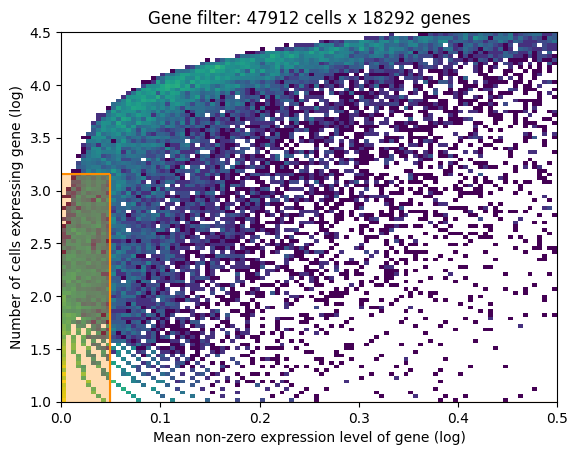

shared genes: 13601
cell types: 11


In [67]:
# permissive gene selection on reference (cell2location recommendation)
selected = filter_genes(
    adata_ref,
    cell_count_cutoff=5,
    cell_percentage_cutoff2=0.03,
    nonz_mean_cutoff=1.12
)
adata_ref = adata_ref[:, selected].copy()
# shared genes between ref and spatial
shared = adata_ref.var_names.intersection(adata.var_names)
adata_ref = adata_ref[:, shared].copy()
adata = adata[:, shared].copy()
print("shared genes:", len(shared))
print("cell types:", adata_ref.obs[label_key].nunique())

## Setup model

First testing celltype and raw counts.  Note: I define cell_type as the cell_type per batch prior to integration and reclassification on integrated (e.g. microglia n= 10281 prior to integration across all batches -> microglia n= 13411 post integration relabeling). "cell_type" (pre batch specific) versus "cell_type_post" (integration) 

In [68]:
#J61_GFP_out = '/research/groups/mackgrp/home/common/Analysis/seqData.Tuyu/RABV_scRNAseq_20260113/Dan_Emerson_analysis/J61_GFP/outs/'
#J61_GFP_file = f'{J61_GFP_out}/J61_GFP_ambient_corrected_v2_mito_doublet_removal_SCT_update.h5ad'
#adata_J61_GFP_sct = sc.read_h5ad(J61_GFP_file)   # or Allen-integrated reference

In [69]:
RegressionModel.setup_anndata(
    adata=adata_ref,
    batch_key=batch_key,
    labels_key=label_key,
    categorical_covariate_keys=None,
)

mod_ref = RegressionModel(adata_ref)   # <-- this defines mod_ref
#mod_ref.view_anndata_setup()

In [72]:
mod_ref

RegressionBackgroundDetectionTech model with the following params: 
n_factors: 11 
n_batch: 1 
Training status: Not Trained

## Ref train

In [73]:
mod_ref.train(
    max_epochs=250,
    accelerator="gpu",
    batch_size=2500,
)


Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/lightning/pytorch/trainer/configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
You are using a CUDA device ('NVIDIA A100-SXM4-80GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision f

Training:   0%|          | 0/250 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=250` reached.


## Ref export signatures

original model performed per nontumor batch (J58, J59, etc.).  Model at "cell_2_location_ref_signatures".  Made an update to perform on singular "collective" batch across all nontumor.  Model update at cell_2_location_ref_signatures (batch_key = "collective").  Since the spatial is not assigned to any particular batch I realized it was better to use a singular batch from ref and train the spatial as "collective" as well.

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.


Sampling local variables, batch:   0%|          | 0/20 [00:00<?, ?it/s]

Sampling global variables, sample:   0%|          | 0/999 [00:00<?, ?it/s]

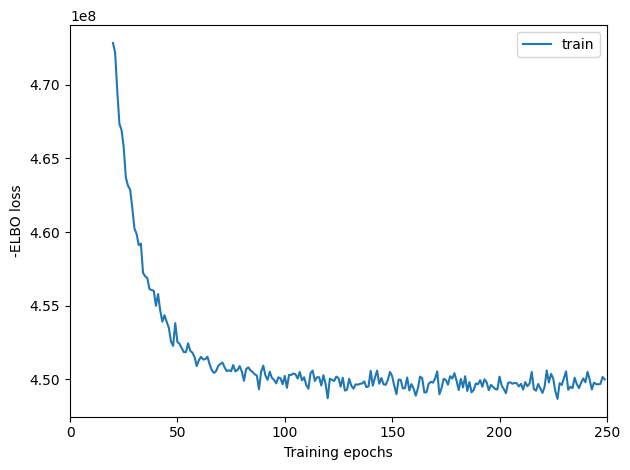

In [74]:
mod_ref.plot_history(20)
adata_ref = mod_ref.export_posterior(
    adata_ref,
    sample_kwargs={
        "num_samples": 1000,
        "batch_size": 2500,
        "accelerator": "gpu"
    }
)

ref = f'{ref_out}/cell_2_location_ref_signatures_collective' #f'{ref_out}/cell_2_location_ref_signatures'
mod_ref.save(ref, overwrite=True)
adata_ref.write(ref + "sc.h5ad")


In [75]:
if "means_per_cluster_mu_fg" in adata_ref.varm.keys():
    inf_aver = adata_ref.varm["means_per_cluster_mu_fg"][
        [f"means_per_cluster_mu_fg_{i}" for i in adata_ref.uns["mod"]["factor_names"]]
    ].copy()
else:
    inf_aver = adata_ref.var[
        [f"means_per_cluster_mu_fg_{i}" for i in adata_ref.uns["mod"]["factor_names"]]
    ].copy()
inf_aver.columns = adata_ref.uns["mod"]["factor_names"]

In [76]:
inf_aver

,CB GABA,CNU-HYa Glut,CNU-LGE GABA,CNU-MGE GABA,CTX-CGE GABA,LSX GABA,Lymphoid NN,MH-LH Glut,Microglia NN,OB-IMN GABA,P GABA
Xkr4,0.017718,0.053856,0.264191,0.116035,2.420416,0.048075,0.008353,0.013437,0.034767,0.037183,1.432793
Sox17,0.075921,0.000809,0.005245,0.000122,0.001303,0.000445,0.003406,0.334408,0.000173,0.001343,0.003942
Lypla1,0.126256,0.241314,0.120737,0.583399,0.174090,0.403197,0.332735,0.406062,0.546669,0.185671,0.358344
Tcea1,0.427061,1.274829,1.977800,1.598532,1.033386,0.753800,1.107626,1.320299,1.604532,1.157199,1.113087
Rgs20,0.017524,1.250116,0.128009,0.049906,0.051598,0.025743,0.008189,0.018829,0.022334,0.334205,7.076777
...,...,...,...,...,...,...,...,...,...,...,...
mt-Nd4l,5.763625,7.774515,4.745681,1.659957,5.228273,2.406554,2.211449,2.388981,4.019979,6.193951,5.678997
mt-Nd4,47.632618,27.409260,13.218473,13.940465,17.787283,18.780264,17.629234,13.055461,23.768505,25.002741,28.946545
mt-Nd5,15.637611,9.587123,4.078425,3.978791,4.977016,5.890752,5.671740,4.714560,8.931174,8.176040,6.848578
mt-Nd6,0.808149,0.794886,0.688131,0.288251,0.493071,0.270612,0.207746,0.301708,0.321560,0.628761,0.509016


## Setup and create spatial mod

Using raw counts from 8 uM 

In [77]:
sr_out = "/research/groups/plummgrp/projects/Visium_855118_Steve_Mack_Siri_09232025/common/Tuyu_Apr2026/Processed/846531_HD_BA_WM_C_DNB_SM_D90-5-A1-GFP_R1/outs"
bin_dir = f"{sr_out}/binned_outputs/square_008um"
adata_raw = sq.read.visium(
    bin_dir,
    counts_file="filtered_feature_bc_matrix.h5",
)

/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [78]:
# match bins/cells
common = adata.obs_names.intersection(adata_raw.obs_names)
print("overlap:", len(common), "/", adata.n_obs)
adata_raw = adata_raw[common].copy()
# copy obs columns you need
for col in ["collective", "in_tissue", "total_counts"]:  # add yours
    if col in adata.obs.columns:
        adata_raw.obs[col] = adata.obs.loc[common, col]
# copy obsm (spatial coords) if missing
if "spatial" in adata.obsm:
    adata_raw.obsm["spatial"] = adata.obsm["spatial"][adata.obs_names.isin(common)]
# replace adata with raw-count object
adata = adata_raw
# remove mt genes
adata.var["mt"] = adata.var_names.str.lower().str.startswith("mt-")
adata = adata[:, ~adata.var["mt"]].copy()

overlap: 78284 / 78284


/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [79]:
adata

AnnData object with n_obs × n_vars = 78284 × 19047
    obs: 'in_tissue', 'array_row', 'array_col', 'total_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'mt'
    uns: 'spatial'
    obsm: 'spatial'

In [80]:
#troubleshooting temporary
import numpy as np
import pandas as pd
# 1) check duplicates
print("duplicate var_names:", adata.var_names.duplicated().sum())
print("duplicate inf_aver index:", inf_aver.index.duplicated().sum())
# 2) make gene names unique
adata.var_names_make_unique()
inf_aver = inf_aver[~inf_aver.index.duplicated(keep="first")].copy()
# 3) intersect and subset (safer with pandas Index)
shared = adata.var_names.intersection(inf_aver.index)
print("shared genes:", len(shared))
adata = adata[:, shared].copy()
inf_aver = inf_aver.loc[shared, :].copy()
print("adata:", adata.shape, " inf_aver:", inf_aver.shape)

duplicate var_names: 6
duplicate inf_aver index: 0
shared genes: 13588
adata: (78284, 13588)  inf_aver: (13588, 11)


In [81]:
# single spatial sample 
adata.obs["collective"] = "nontumor"
adata.obs["collective"] = adata.obs["collective"].astype("category")

# intersect genes with reference signatures (if not done already)
intersect = np.intersect1d(adata.var_names, inf_aver.index)
adata = adata[:, intersect].copy()
inf_aver = inf_aver.loc[intersect, :].copy()

Cell2location.setup_anndata(adata=adata, batch_key="collective")
mod = Cell2location(
    adata,
    cell_state_df=inf_aver,
    N_cells_per_location=2,    # ~1-2 for 8 µm HD; use 4 for 16 µm
    detection_alpha=200,       # use 20 if strong technical variation
)

## Train spatial model

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/lightning/pytorch/trainer/configuration_validator.py:68: You passe

Training:   0%|          | 0/30000 [00:00<?, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter serve

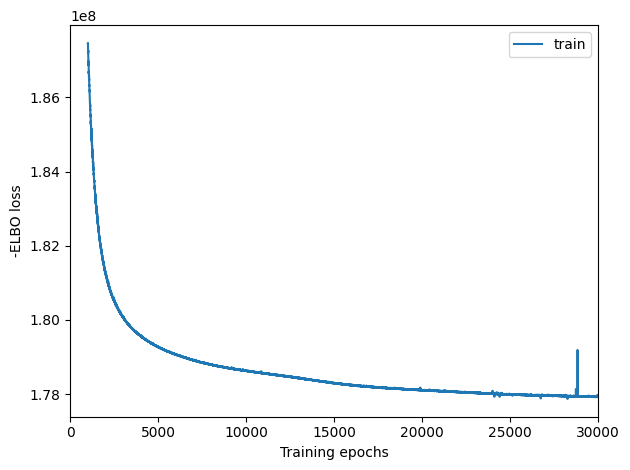

In [82]:
mod.train(
    max_epochs=30000,
    batch_size=None,
    train_size=1,
    accelerator="gpu"
)
mod.plot_history(1000)

## Export spatial posterior

In [ ]:
adata = mod.export_posterior(
    adata,
    sample_kwargs={
        "num_samples": 1000,
        "batch_size": adata.n_obs,   # or mod.adata.n_obs
        "accelerator": "gpu"
    }
)
run_name = "./results_cell2location/c2l_spatial_008um_6_30_" + label
mod.save(run_name, overwrite=True)
adata.write(f"{run_name}/sp.h5ad")

## add cell2location to loupe file

In [240]:
#adata = sc.read_h5ad("results_cell2location/c2l_spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_008um/sp.h5ad")
adata = sc.read_h5ad("../results_cell2location/c2l_spatial_" + label + "_v2/sp.h5ad")

In [241]:
cell2loc_series = adata.obs["dominant_celltype"].rename("cell2location")

# Map onto loupe_export by barcode — unmatched barcodes get NaN
loupe_export["cell2location"] = loupe_export["Barcode"].map(cell2loc_series)

In [242]:
filename = "../for_loupe/spatial_" + label +  "_for_loupe.csv"
loupe_export.to_csv(filename, index=False,na_rep="Unknown")

In [243]:
loupe_export

,Barcode,tlcelltype_assigned,celltype_assigned_norm,nnls_celltype_assigned,norm_tltumscore_C11orf95_relafus1,norm_tlscore_gfp_probe,cellestimate,cellestimate_right,predicted.id,cell2location
0,s_008um_00260_00253-1,Unknown,tlscore_CNU-HYa Glut,nnls_CNU-HYa Glut,norm_tltumscore_C11orf95_relafus1,not gfp,MY Glut,MY Glut,P GABA,P GABA
1,s_008um_00819_00322-1,Unknown,tlscore_MB GABA,nnls_MB GABA,norm_tltumscore_C11orf95_relafus1,not gfp,TH Glut,TH Glut,CNU-MGE GABA,NaN
2,s_008um_00469_00254-1,tlscore_Immune,tlscore_TH Glut,nnls_TH Glut,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,CNU-HYa Glut,P GABA
3,s_008um_00674_00375-1,tlscore_CNU-HYa GABA,tlscore_CNU-HYa GABA,nnls_CNU-HYa GABA,norm_tltumscore_C11orf95_relafus1,not gfp,TH Glut,TH Glut,CB GABA,P GABA
4,s_008um_00220_00651-1,Unknown,tlscore_MB GABA,nnls_MB GABA,norm_tltumscore_C11orf95_relafus1,not gfp,CB GABA,CB GABA,CB GABA,NaN
...,...,...,...,...,...,...,...,...,...,...
208869,s_008um_00065_00410-1,tlscore_MY GABA,tlscore_Astro-Epen,nnls_MY GABA,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,CNU-HYa Glut,P GABA
208870,s_008um_00506_00476-1,tlscore_Vascular,tlscore_Vascular,nnls_HY Glut,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,CB GABA,CNU-HYa Glut
208871,s_008um_00068_00328-1,tlscore_CB GABA,tlscore_IT-ET Glut,nnls_CB GABA,norm_tltumscore_C11orf95_relafus1,not gfp,Microglia NN,Microglia NN,OB-IMN GABA,P GABA
208872,s_008um_00655_00060-1,tlscore_NP-CT-L6b Glut,tlscore_CNU-HYa GABA,nnls_NP-CT-L6b Glut,norm_tltumscore_C11orf95_relafus1,not gfp,MY Glut,MY Glut,CB GABA,NaN


In [244]:
filename

'../for_loupe/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_7_D1_GFP_R1_008um_for_loupe.csv'

In [192]:
adata.obs["dominant_celltype"] == 

s_008um_00547_00611-1    P GABA
s_008um_00359_00037-1    P GABA
s_008um_00221_00585-1    P GABA
s_008um_00498_00370-1    P GABA
s_008um_00388_00048-1    P GABA
                          ...  
s_008um_00559_00432-1    P GABA
s_008um_00506_00476-1    P GABA
s_008um_00214_00470-1    P GABA
s_008um_00255_00356-1    P GABA
s_008um_00565_00596-1    P GABA
Name: dominant_celltype, Length: 70823, dtype: category
Categories (7, object): ['CB GABA', 'CNU-LGE GABA', 'CTX-CGE GABA', 'MH-LH Glut', 'Microglia NN', 'OB-IMN GABA', 'P GABA']